In [2]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import warnings
import numpy as np
import pandas as pd 
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

from eudr import boundaries as bd, rasterstream as rs, synthentic as syn, validation as val
from eudr.config import load_config, run_dirs, slugify, resolve_path
from eudr.manifest import write_manifest, sidecar_hashes


warnings.filterwarnings("ignore",category=UserWarning)
cfg = load_config(ROOT)
dirs = run_dirs(cfg)



                                    

In [3]:
gpkg = dirs["gis"]/"study_area.gpkg"
districts = gpd.read_file(gpkg, layer="ref_districts")
subcounties = gpd.read_file(gpkg, layer="ref_subcounties")

found = subcounties.groupby("district").size().rename("polygon_in_file")
expected = pd.Series(cfg["boundaries"].get("expected_subcounties",{}), name ="your_count")
check = pd.concat([found, expected], axis=1)
display(check)
if(check["polygon_in_file"] != check["your_count"]).any():
    print("WARNING: the boundary file does not match your subcounty counts. Subcounty-level fields "
          "(enumerators, admin mismatch) will follow the polygons in the file.")


,polygon_in_file,your_count
Buikwe,4,3
Kyotera,1,1


In [4]:
SYN = cfg["synthetic"]
rng = np.random.default_rng(SYN["seed"])
wc_year = cfg["forest_data"]["worldcover"]["year"]

parts = []
for _, d in districts.iterrows():
    dname, slug = d["district"], slugify(d["district"])
    forest_arr, tr, _ = rs.read_tif(dirs["rasters"] / f"{slug}_forest_2020.tif")
    cls, _, _ = rs.read_tif(dirs["rasters"] / f"{slug}_loss_class.tif")
    wc, _, _ = rs.read_tif(dirs["rasters"] / f"{slug}_worldcover_{wc_year}.tif")
    subs = subcounties[subcounties["district"] == dname]
    print(f"{dname}: generating {SYN['plots_per_district']} synthetic plots")
    parts.append(syn.generate_district(dname, subs, forest_arr == 1, cls, wc, tr,
                                       int(d["utm_epsg"]), SYN, rng))

synthetic = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=4326)

truth_cols = [c for c in synthetic.columns if c.startswith("_truth")]
truth = pd.DataFrame(synthetic[["plot_id"] + truth_cols])
plot_file = synthetic.drop(columns=truth_cols)            # the validator never sees the answers

out_dir = ROOT / "data" / "synthetic"
out_dir.mkdir(parents=True, exist_ok=True)
plot_file.to_file(out_dir / "plots_synthetic.geojson", driver="GeoJSON")
truth.to_csv(out_dir / "plots_synthetic_truth.csv", index=False)

print("\nPlots per district and forest scenario:")
display(pd.crosstab(truth["plot_id"].str[4:7], truth["_truth_scenario"]))
print("Injected errors:", truth["_truth_issue"].value_counts().drop("none", errors="ignore").to_dict())

Buikwe: generating 200 synthetic plots
  note: no 'loss_outside' pixels in this district; moving 14 plots to 'clean'
Kyotera: generating 200 synthetic plots
  note: no 'loss_outside' pixels in this district; moving 14 plots to 'clean'
  note: only one subcounty polygon in this district, so admin_mismatch cases were skipped

Plots per district and forest scenario:


_truth_scenario,clean,inside_forest,loss_in_forest,near_forest
plot_id,,,,
BUI,122,12,15,51
KYO,123,12,16,49


Injected errors: {'overlap_other_farmer': 8, 'missing_coords': 8, 'point_over_4ha': 8, 'invalid_polygon': 8, 'area_mismatch': 8, 'low_precision': 8, 'duplicate_farmer_plot': 6, 'outside_district': 6, 'tiny_area': 6, 'coords_swapped': 6, 'huge_area': 4, 'admin_mismatch': 4, 'future_date': 4}


In [5]:
plots_path = resolve_path(cfg, cfg["plots"]["input_path"])
plots = gpd.read_file(plots_path)
print(f"Loaded {len(plots)} plots from {plots_path.name}")
print("Geometry types:", plots.geom_type.fillna("none").value_counts().to_dict())

missing_cols = val.missing_template_columns(plots, cfg["template"])
print("Columns missing from the template:", missing_cols or "none")
plots.drop(columns="geometry").head()

Loaded 400 plots from plots_synthetic.geojson
Geometry types: {'Polygon': 235, 'Point': 157, 'none': 8}
Columns missing from the template: none


,plot_id,farmer_id,farmer_name,cooperative_or_group,enumerator_id,collection_date,survey_version,district,subcounty,geometry_type,...,stumped_or_rehabilitated,wilt_disease_observed,est_annual_yield_kg,certification_scheme,certification_status,fertiliser_use,hired_labour,synthetic_flag,lon,lat
0,SYN-BUI-0001,F-BUI-0157,Synthetic Farmer 0157,Coop-BUI-A,E01,2026-08-30,v1,Buikwe,Njeru Municipality,point,...,no,none,238.0,none,n/a,no,yes,True,33.206041,0.347109
1,SYN-BUI-0002,F-BUI-0018,Synthetic Farmer 0018,Coop-BUI-B,E04,2026-10-22,v1,Buikwe,KCCA,polygon,...,no,low,154.0,NaN,n/a,no,no,True,32.929782,0.370861
2,SYN-BUI-0003,F-BUI-0070,Synthetic Farmer 0070,Coop-BUI-C,E02,2026-08-05,v1,Buikwe,Lugazi Municipality,polygon,...,no,none,NaN,none,n/a,yes,yes,True,32.907331,0.330534
3,SYN-BUI-0004,F-BUI-0169,Synthetic Farmer 0169,Coop-BUI-C,E01,2026-08-29,v1,Buikwe,Njeru Municipality,polygon,...,no,none,NaN,none,n/a,yes,no,True,33.147526,0.408357
4,SYN-BUI-0005,F-BUI-0067,Synthetic Farmer 0067,Coop-BUI-C,E02,2026-10-16,v1,Buikwe,Njeru Municipality,polygon,...,no,low,NaN,none,n/a,yes,no,True,33.181043,0.391121


In [6]:
raw = bd.load_admin(resolve_path(cfg, cfg["boundaries"]["path"])).to_crs(4326)
raw, _ = bd.clean_geometries(raw)
uganda = shapely.make_valid(shapely.union_all(raw.geometry.values))
study = shapely.make_valid(shapely.union_all(subcounties.geometry.values))
print("Uganda outline and study area ready")

Uganda outline and study area ready


In [7]:
plots_val, issues = val.validate(plots, uganda, study, subcounties,
                                 cfg["validation"], cfg["eudr"], cfg["template"])

n = len(plots_val)
kpi = pd.DataFrame({
    "indicator": ["Plots", "Pass", "Review", "Reject", "Mean completeness (%)",
                  "Plots as polygons (%)", "Total declared area (ha)"],
    "value": [n,
              int((plots_val["status"] == "pass").sum()),
              int((plots_val["status"] == "review").sum()),
              int((plots_val["status"] == "reject").sum()),
              round(plots_val["completeness_pct"].mean(), 1),
              round(plots_val.geom_type.isin(["Polygon", "MultiPolygon"]).mean() * 100, 1),
              round(plots_val["declared_area_ha"].sum(), 1)],
})
display(kpi)

issue_counts = (issues.groupby(["check", "severity"]).size().reset_index(name="plots")
                .sort_values(["severity", "plots"], ascending=[True, False]))
display(issue_counts)

,indicator,value
0,Plots,400.0
1,Pass,282.0
2,Review,72.0
3,Reject,46.0
4,Mean completeness (%),95.2
5,Plots as polygons (%),58.8
6,Total declared area (ha),793.8


,check,severity,plots
10,needs_polygon,critical,10
4,duplicate_farmer_geometry,critical,8
6,invalid_geometry,critical,8
9,missing_geometry,critical,8
11,outside_study_area,critical,6
12,outside_uganda,critical,6
13,overlap_other_farmer,review,28
5,gps_poor,review,14
1,area_mismatch,review,11
8,low_precision,review,8


In [8]:
by_district = val.summarise(plots_val, "district")
by_subcounty = val.summarise(plots_val, "subcounty")
by_enumerator = val.summarise(plots_val, "enumerator_id")
by_coop = val.summarise(plots_val, "cooperative_or_group")
display(by_district)
display(by_enumerator.sort_values("mean_completeness_pct"))

,district,plots,passed,review,rejected,mean_completeness_pct,declared_area_ha,pass_rate_pct
0,Buikwe,200,143,35,22,94.5,391.9,71.5
1,Kyotera,200,139,37,24,95.9,401.9,69.5


,enumerator_id,plots,passed,review,rejected,mean_completeness_pct,declared_area_ha,pass_rate_pct
0,E01,182,126,30,26,94.3,307.6,69.2
1,E02,177,131,29,17,95.5,298.7,74.0
3,E04,4,1,2,1,95.5,68.6,25.0
4,E05,19,11,8,0,97.2,31.5,57.9
5,E06,14,11,1,2,97.7,83.5,78.6
2,E03,4,2,2,0,98.8,3.8,50.0


In [9]:
test = pd.DataFrame(plots_val.drop(columns="geometry")).merge(truth, on="plot_id", how="left")

rows = []
for issue, flag in val.TRUTH_TO_FLAG.items():
    inj = test[test["_truth_issue"] == issue]
    if len(inj):
        rows.append({"injected_issue": issue, "expected_flag": flag, "injected": len(inj),
                     "caught": int(inj[flag].sum()), "recall_pct": round(inj[flag].mean() * 100)})
validator_test = pd.DataFrame(rows)
display(validator_test)

untouched = test[test["_truth_issue"] == "none"]
print(f"Plots with no injected error rejected anyway: {(untouched['status'] == 'reject').mean() * 100:.1f}%")

,injected_issue,expected_flag,injected,caught,recall_pct
0,missing_coords,missing_geometry,8,8,100
1,coords_swapped,outside_uganda,6,6,100
2,point_over_4ha,needs_polygon,8,8,100
3,invalid_polygon,invalid_geometry,8,8,100
4,tiny_area,area_tiny,6,6,100
5,huge_area,area_huge,4,4,100
6,overlap_other_farmer,overlap_other_farmer,8,8,100
7,duplicate_farmer_plot,duplicate_farmer_geometry,6,4,67
8,outside_district,outside_study_area,6,6,100
9,area_mismatch,area_mismatch,8,8,100


Plots with no injected error rejected anyway: 1.6%


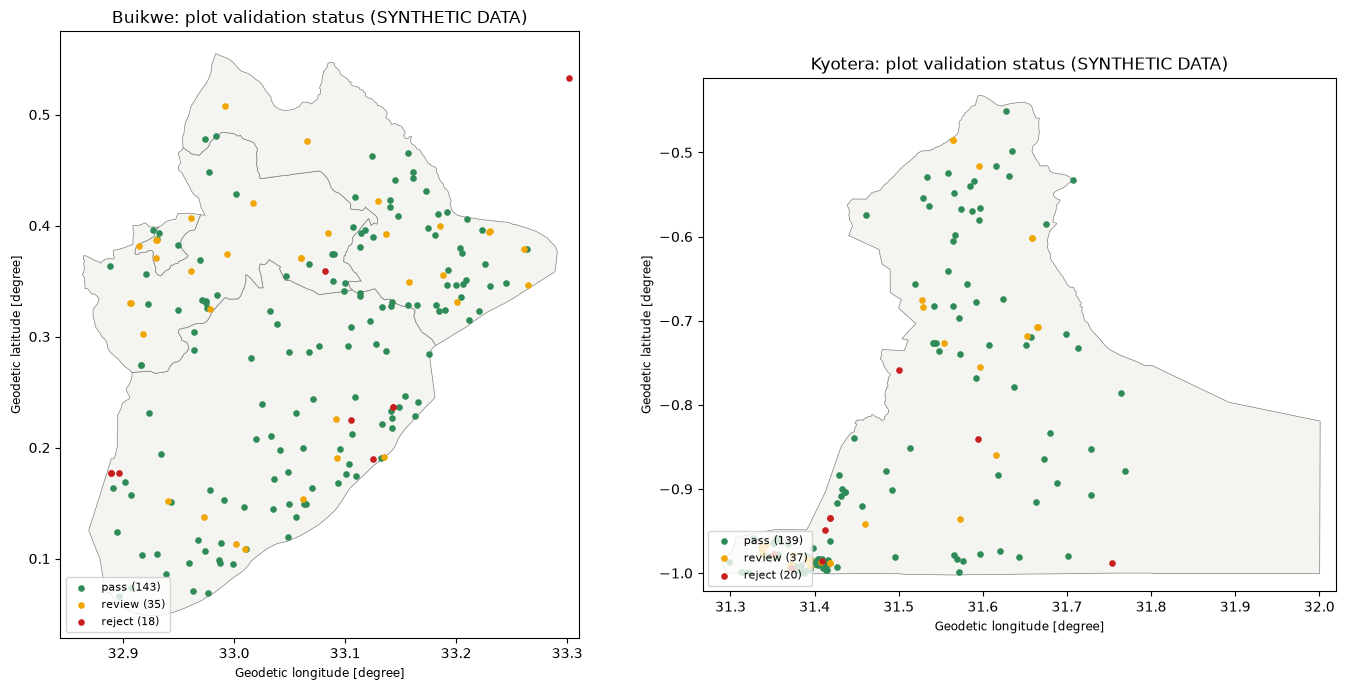

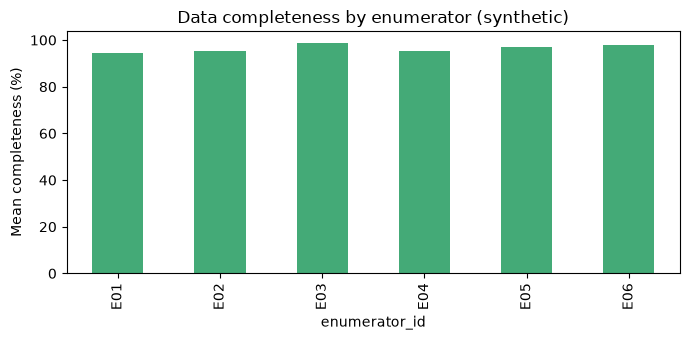

In [10]:
colors = {"pass": "#2e8b57", "review": "#f0a500", "reject": "#c81e1e"}
fig, axes = plt.subplots(1, len(districts), figsize=(7 * len(districts), 7), squeeze=False)

for ax, (_, d) in zip(axes[0], districts.iterrows()):
    sub = subcounties[subcounties["district"] == d["district"]]
    sub.plot(ax=ax, color="#f4f4f0", edgecolor="grey", linewidth=0.5)
    v = plots_val[plots_val.geometry.notna() & (plots_val["district"] == d["district"])]
    c = shapely.centroid(v.geometry.to_numpy())
    x, y = shapely.get_x(c), shapely.get_y(c)
    for status, col in colors.items():
        m = (v["status"] == status).to_numpy()
        ax.scatter(x[m], y[m], s=14, color=col, label=f"{status} ({m.sum()})", zorder=3)
    minx, miny, maxx, maxy = sub.total_bounds
    ax.set_xlim(minx - 0.02, maxx + 0.02)
    ax.set_ylim(miny - 0.02, maxy + 0.02)
    ax.set_title(f"{d['district']}: plot validation status (SYNTHETIC DATA)")
    ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(dirs["maps"] / "plot_validation_status.png", dpi=200)
plt.show()

ax = by_enumerator.set_index("enumerator_id")["mean_completeness_pct"].plot.bar(figsize=(7, 3.5), color="#4a7")
ax.set_ylabel("Mean completeness (%)")
ax.set_title("Data completeness by enumerator (synthetic)")
plt.tight_layout()
plt.savefig(dirs["maps"] / "completeness_by_enumerator.png", dpi=200)
plt.show()

In [11]:
# GeoPackage for QGIS (points and polygons in separate layers)
out_gpkg = dirs["gis"] / "plots_validated.gpkg"
if out_gpkg.exists():
    out_gpkg.unlink()
has = plots_val.geometry.notna() & ~plots_val.geometry.is_empty
plots_val[has & plots_val.geom_type.isin(["Polygon", "MultiPolygon"])].to_file(out_gpkg, layer="plots_polygons", driver="GPKG")
plots_val[has & (plots_val.geom_type == "Point")].to_file(out_gpkg, layer="plots_points", driver="GPKG")
issues.to_csv(dirs["reports"] / "plot_issues.csv", index=False)

# Excel report
def write_sheet(xl, df, name, status_col=None):
    df.to_excel(xl, sheet_name=name, index=False)
    ws = xl.sheets[name]
    ws.freeze_panes(1, 0)
    for k, col in enumerate(df.columns):
        longest = int(df[col].astype(str).str.len().quantile(0.9)) + 2 if len(df) else 10
        ws.set_column(k, k, min(40, max(len(str(col)) + 2, longest)))
    if status_col is not None and len(df):
        k = list(df.columns).index(status_col)
        for value, color in (("reject", "#F8CBAD"), ("review", "#FFE699"), ("pass", "#C6E0B4")):
            ws.conditional_format(1, k, len(df), k, {"type": "cell", "criteria": "==",
                                  "value": f'"{value}"', "format": xl.book.add_format({"bg_color": color})})

flag_cols = [c for c in val.SEVERITY if c in plots_val.columns]
plot_table = pd.DataFrame(plots_val.drop(columns="geometry"))

with pd.ExcelWriter(dirs["reports"] / "plot_data_quality_report.xlsx", engine="xlsxwriter") as xl:
    write_sheet(xl, kpi, "kpi")
    write_sheet(xl, by_district, "by_district")
    write_sheet(xl, by_subcounty, "by_subcounty")
    write_sheet(xl, by_enumerator, "by_enumerator")
    write_sheet(xl, by_coop, "by_cooperative")
    write_sheet(xl, issue_counts, "issue_counts")
    write_sheet(xl, issues, "issues")
    write_sheet(xl, plot_table, "plots", status_col="status")
    write_sheet(xl, validator_test, "validator_test")
    write_sheet(xl, pd.DataFrame({"note": [
        "SYNTHETIC DATA: every plot, farmer and coordinate in this report is generated for testing.",
        f"Polygon rule: plots of {cfg['eudr']['polygon_threshold_ha']} ha or more need a polygon.",
        f"Area limits: {cfg['validation']['min_area_ha']} to {cfg['validation']['max_area_ha']} ha.",
        "Status: reject = at least one critical check failed; review = warnings only; pass = no flags.",
        "Completeness = 70% core fields + 30% recommended fields (config.yaml).",
        "Coordinate precision is flagged below 4 decimals; trailing zeros cannot be told apart from rounding.",
        "Deforestation screening is done in notebook 04, not here."]}), "notes")

write_manifest(dirs["manifests"], "03_plots_validation", {
    "plot_file": str(plots_path),
    "plots": int(len(plots_val)),
    "synthetic": bool(plots_val["synthetic_flag"].fillna(False).all()) if "synthetic_flag" in plots_val else None,
    "seed": cfg["synthetic"]["seed"],
    "boundary_file_hashes": sidecar_hashes(resolve_path(cfg, cfg["boundaries"]["path"])),
    "validation_settings": cfg["validation"],
    "status_counts": plots_val["status"].value_counts().to_dict(),
})
print("Saved:", out_gpkg)
print("Saved:", dirs["reports"] / "plot_data_quality_report.xlsx")

Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\plots_validated.gpkg
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\reports\plot_data_quality_report.xlsx
